# 2) Creating mock populations of primaries

In [1]:
from scipy.stats import uniform
import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table

In [ ]:
import json
import sys

with open('./config.json', 'r', encoding='utf-8') as f:
    d = json.load(f)

sys.path.append(d["wrapper_path"])

from Wrapper import SimulateAstrometry, style, utils
from Wrapper.SimulateAstrometry import simulate_population_astrometry as simpopast

In [3]:
import isochrones
import isochrones.populations as pop

Holoviews not imported. Some visualizations will not be available.
PyMultiNest not imported.  MultiNest fits will not work.


In this notebook I will show how to use the `isochrones` package to generate primaries, and then compute the rates of each solution type for some particular companion models

## `isochrones.py`

The `isochrones` package is quite an easy-to-use package to generate primaries (and binaries!) from isochrones. It natively comes with `mist` isochrones.

It can be downloaded and read about here: https://isochrones.readthedocs.io/en/latest/, I followed their simple instructions in the ${\tt Simulating stellar populations}$ example.

I'm not sure if it's just an issue with my machine, but the mist isochrones that are supposed to automatically download didn't work. They can be downloaded here https://zenodo.org/records/4056544, and placed into the `.isochrones` folder likely placed into your home directory. Otherwise just ask Claude or something idk

### Generate the primaries

In [4]:
mist = isochrones.get_ichrone("mist")
imf = isochrones.priors.SalpeterPrior(bounds=(0.6,2))
sfh = pop.StarFormationHistory(dist=uniform(0,10))

feh = isochrones.priors.GaussianPrior(-0.2, 0.2)
AV = isochrones.priors.FlatPrior(bounds=[0,1])

pop = pop.StarPopulation(mist, imf=imf, fB=0.4, gamma=0.3, sfh=sfh, feh=feh, AV=AV, distance=100)

In [5]:
df = pop.generate(10000)

### Construct the catalogue

In [6]:
reduced_table = df[["mass_0", "age_0", "A_G", "feh_0", "BP_mag", "RP_mag", "G_mag", "distance_0"]]
final_table = Table()
final_table["mass"] = reduced_table["mass_0"]
final_table["age"] = reduced_table["age_0"]
final_table["A_G"] = reduced_table["A_G"]
final_table["feh"] = reduced_table["feh_0"]
final_table["bp_rp"] = reduced_table["BP_mag"] - reduced_table["RP_mag"]
final_table["parallax"] = 1000 / reduced_table["distance_0"]
final_table["phot_g_mean_mag"] = reduced_table["G_mag"] + 5 * np.log10(reduced_table["distance_0"] / 10) + reduced_table["A_G"]
final_table["abs_G_mag"] = reduced_table["G_mag"]
# assign random sky positions to the final table with a proper motion limit of 50 km/s
utils.random_sky_positions(final_table, dispersion=30)

In [7]:
final_table.write("./data/popsynth_parent_sample.fits", format="fits", overwrite=True)

### Simulate some companions

Let's select
- eccentricity: circular
- period: log-uniform between $10^1$ and $10^5$ days
- companions: power-law mass ratio index=0.5 so higher masses are slightly more common
- Source isotropically distributed between 100 and 500pc

In [4]:
parent_sample = Table.read("./data/popsynth_parent_sample.fits", format="fits")

In [ ]:
objs, astrometry_results = simpopast(object_count=20000, catalogue=parent_sample,  # no specified binary fraction -> all binaries
                                        astrometry_function=SimulateAstrometry.gw.dr3_astrometric_pipeline, # Gaia DR3 astrometric pipeline
                                        period_model=utils.uniform_distribution, period_kwargs={"lims": (1, 4), "log": True}, # log-uniform distribution of periods
                                        eccentricity_model=utils.constant_distribution, ecc_kwargs={"value": 0}, # all circular
                                        companion_mass_model=utils.power_law_distribution, m_kwargs={"lims": (0.1, 1), "index": 0.5}, # prefer higher mass ratio systems
                                        flux_ratio_model=utils.flux_ratio_power_law, f_kwargs={"index": 3.5}, # flux ratios determined by simple mass-luminosity relationship
                                        reassign_parallaxes=True, plx_kwargs={"dist_range": (100, 500)}, # set the distance to be 0.1-1 kpc
                                        return_fits=True, return_statistics=True, n_jobs=-1)
utils.postproces_solution_type(objs, astrometry_results)
processed_res = utils.postprocess_fits(astrometry_results)

(1) Assigning companions to 20000 sources...
(1) Reassigned parallaxes and adjusted magnitudes. 10148 sources G>19 were removed.
(2) Computing astrometry for 9852 sources...


Computing astrometry for all sources...:   0%|          | 0/9852 [00:00<?, ?it/s]

/home/bepennell/research/GaiamockWrapper/.wrapperenv/lib/python3.10/site-packages/numpy/_core/numeric.py:353: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(a, fill_value, casting='unsafe')


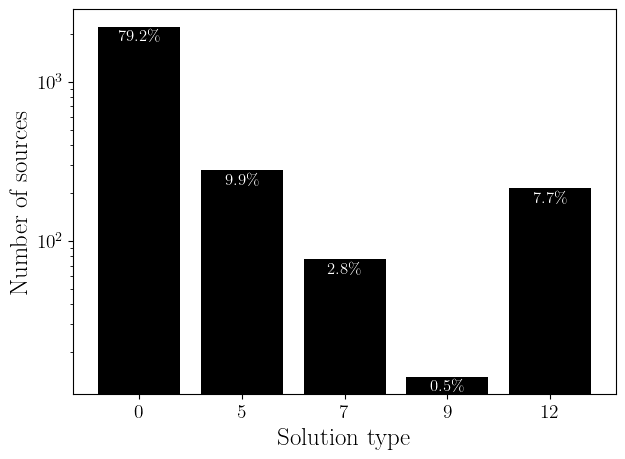

In [6]:
soltypes = [0,5,7,9,12]
counts, bins, _ = plt.hist(np.digitize(objs[objs["phot_g_mean_mag"] < 17]["solution_type"], soltypes, right=True), bins=np.arange(len(soltypes)+1)-0.5, rwidth=0.8)
plt.xticks(ticks=np.arange(len(soltypes)), labels=soltypes)
plt.xlabel("Solution type")
plt.ylabel("Number of sources")
plt.yscale("log")

rates = counts / counts.sum() * 100
for i, (count, rate) in enumerate(zip(counts, rates)):
    if count > 0:
        plt.text(i, count * 0.78, f"{rate:.1f}\%", c="white", fontsize=12, ha="center", va="bottom")

plt.show()

## Resampling for investigating things!

`utils.resample_table()` let's you take a table of objects (like the one computed above), and resample the parent population such that one of the parameters follows a different distribution model.

This is powerful because we have already computed the astrometry+cascade for all these sources, so we can quickly obtain how the new population would look propagated through the selection function. This is important, because you don't need to simulate a bunch of different models, you just need to simulate a bunch of sources and resample them to look at different models.

If you want to then fit the binary model parameters this way - contact me, I have a scheme. Two actually. One of them is even mathematically rigorous (don't worry about the other)

currently our mass ratio distribution is a power law, but what if it were constant instead?

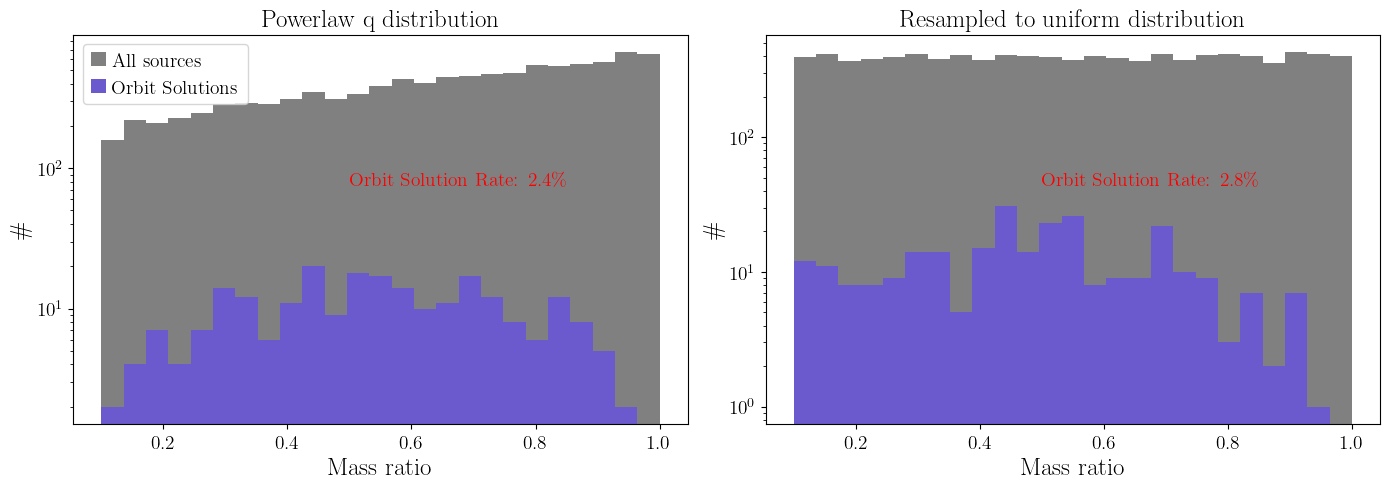

In [16]:
const_q_table = utils.resample_table(objs, param="q", resample_func=utils.uniform_distribution, resample_kwargs={"lims": (0.1, 1)})

bins = np.linspace(0.1, 1, 26)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

rate = np.sum(objs["solution_type"] == 12) / len(objs) * 100
ax = axs[0]
tbins = ax.hist(objs["q"], bins=bins, color="grey", label="All sources")
ax.hist(objs[objs["solution_type"] == 12]["q"], bins=tbins[1], color="slateblue", label="Orbit Solutions")
ax.legend(frameon=True)
ax.set_xlabel("Mass ratio")
ax.set_ylabel("\#")
ax.set_yscale("log")
ax.set_title("Powerlaw q distribution")
ax.text(0.45, 0.65, f"Orbit Solution Rate: {rate:.1f}\%", color="red", transform=ax.transAxes, fontsize=14, verticalalignment='top')

rate = np.sum(const_q_table["solution_type"] == 12) / len(const_q_table) * 100
ax = axs[1]
tbins = ax.hist(const_q_table["q"], bins=bins, color="grey", label="All sources")
ax.hist(const_q_table[const_q_table["solution_type"] == 12]["q"], bins=tbins[1], color="slateblue", label="Orbit Solutions")
ax.set_xlabel("Mass ratio")
ax.set_ylabel("\#")
ax.set_yscale("log")
ax.set_title("Resampled to uniform distribution")
ax.text(0.45, 0.65, f"Orbit Solution Rate: {rate:.1f}\%", color="red", transform=ax.transAxes, fontsize=14, verticalalignment='top')

plt.tight_layout()
plt.show()

and what if the period distribution were log-normal instead? Being careful to make the sampling function operate in log space

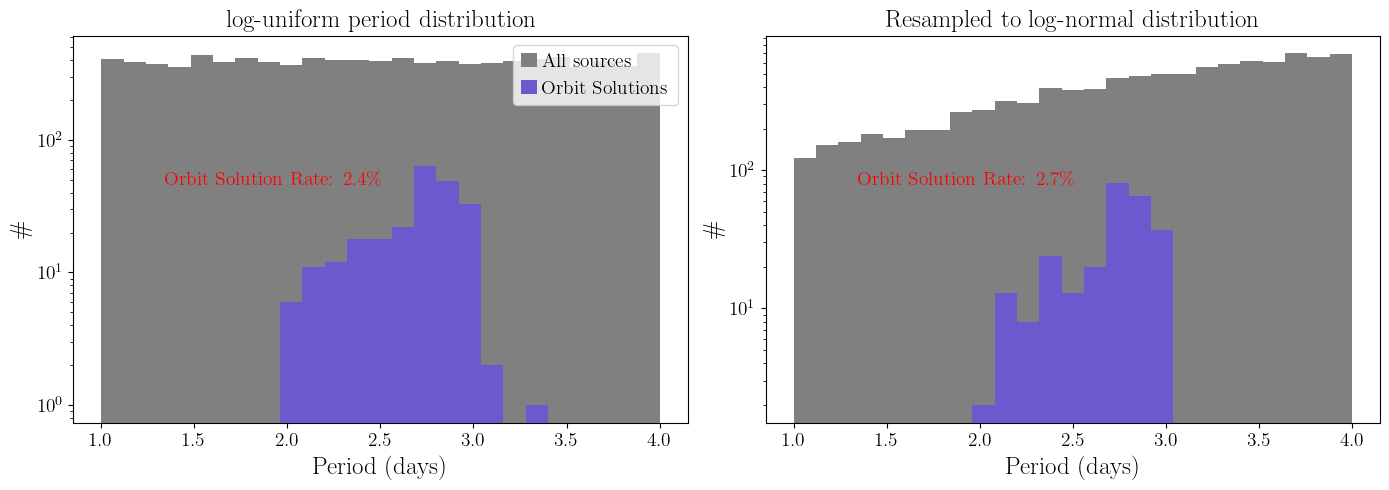

In [24]:
lognorm_p_table = utils.resample_table(objs, param="period", resample_func=utils.normal_distribution, resample_kwargs={"lims": (1, 4), "gaussian_params": (5, 2), "log": True})

bins = np.linspace(1, 4, 26)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

rate = np.sum(objs["solution_type"] == 12) / len(objs) * 100
ax = axs[0]
tbins = ax.hist(np.log10(objs["period"]), bins=bins, color="grey", label="All sources")
ax.hist(np.log10(objs[objs["solution_type"] == 12]["period"]), bins=tbins[1], color="slateblue", label="Orbit Solutions")
ax.legend(frameon=True) 
ax.set_xlabel("Period (days)")
ax.set_ylabel("\#")
ax.set_yscale("log")
ax.set_title("log-uniform period distribution")
ax.text(0.15, 0.65, f"Orbit Solution Rate: {rate:.1f}\%", color="red", transform=ax.transAxes, fontsize=14, verticalalignment='top')

rate = np.sum(lognorm_p_table["solution_type"] == 12) / len(lognorm_p_table) * 100
ax = axs[1]
tbins = ax.hist(np.log10(lognorm_p_table["period"]), bins=bins, color="grey", label="All sources")
ax.hist(np.log10(lognorm_p_table[lognorm_p_table["solution_type"] == 12]["period"]), bins=tbins[1], color="slateblue", label="Orbit Solutions")
ax.set_xlabel("Period (days)")
ax.set_ylabel("\#")
ax.set_title("Resampled to log-normal distribution")
ax.set_yscale("log")
ax.text(0.15, 0.65, f"Orbit Solution Rate: {rate:.1f}\%", color="red", transform=ax.transAxes, fontsize=14, verticalalignment='top')

plt.tight_layout()
plt.show()